# 38. Figures for the Methodology section

Three figures for the paper, sized for the svproc text width (about 4.8 inches), saved as PNG (300 dpi) and PDF in `outputs/figures/methodology/` and logged to ClearML.

| file | what it shows |
|---|---|
| `fig_class_sampler` | training clips per class, the 150 clip limit for the limited sample classes, and the class balanced sampler target of 300 |
| `fig_selection` | the court aware selection: one clip, full frame with both players boxed, then three zoomed frames with the skeletons of the near (blue) and far (orange) player |
| `fig_augmentation` | one real skeleton clip, and the same clip under the basic and the advanced policy |

The wrong player examples figure comes from notebook 35 (`outputs/results/wrong_player_examples.png`) and is not redrawn here. Reads data only; trains nothing, so it can run while another notebook is using the GPU.

In [1]:
import glob
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from clearml import Task

try:
    import cv2
except ImportError:
    cv2 = None

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
RAW_VIDEOS = os.environ.get("BADMINTON_RAW_VIDEOS", f"{DATA}/raw")
for p in (REPO, f"{REPO}/two_player"):
    sys.path.insert(0, p)
import dataset as ds

FIG = f"{OUTPUTS}/figures/methodology"
os.makedirs(FIG, exist_ok=True)
SEL_RAW, SEL_BOX = f"{DATA}/keypoints_sel_raw", f"{DATA}/boxes_sel"
OLD_INTERP = f"{DATA}/keypoints_interp"
SEL_INTERP = f"{DATA}/keypoints_sel_interp"
NEAR, FAR, GREY, ACCENT = "#4c72b0", "#dd8452", "#8c8c8c", "#55a868"
CONF_MIN, N_TARGET = 0.3, 30
WIDTH = 4.8                                         # inches, the svproc text width
plt.rcParams.update({"figure.dpi": 130, "font.size": 7, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 6})
task = Task.init(project_name="BadmintonPoseAnalysis/results", task_name="methodology_figures", task_type=Task.TaskTypes.data_processing,
                 tags=["paper", "figures", "methodology"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
logger = task.get_logger()


def save(fig, name):
    fig.savefig(f"{FIG}/{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{FIG}/{name}.pdf", bbox_inches="tight")
    logger.report_matplotlib_figure(name, "methodology", figure=fig, iteration=0, report_interactive=False)
    print("saved", f"{FIG}/{name}.png")

ClearML Task: created new task id=6451aba093c84d6aa8ecbe6fa1780502
2026-10-10 08:45:50,044 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/b58b0baede1f4527b9f5e9bdceb07833/tasks/6451aba093c84d6aa8ecbe6fa1780502/output/log
ClearML Monitor: Could not detect iteration reporting, falling back to iterations as seconds-from-start


In [2]:
with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)
TARGET = RECIPE["target_per_class"]
RARE_THRESHOLD = 150
clean_log = pd.read_csv(f"{DATA}/keypoints_sel_interp_log.csv").set_index("filepath")
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
manifest = manifest[manifest["filepath"].isin(clean_log.index)].reset_index(drop=True)
manifest = manifest[clean_log.loc[manifest["filepath"], "near_cov"].to_numpy() > 0].reset_index(drop=True)
manifest["far_found"] = clean_log.loc[manifest["filepath"], "far_cov"].to_numpy() >= 0.5
class_names = sorted(manifest["class_name"].unique())
train_counts = manifest[manifest["split"] == "train"]["class_name"].value_counts().reindex(class_names)
print(manifest["split"].value_counts().to_dict(), "| target per class", TARGET)

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
{'train': 6247, 'test': 782, 'val': 781} | target per class 300


## Figure 1: class distribution and the class balanced sampler

saved /workspace/outputs/figures/methodology/fig_class_sampler.png


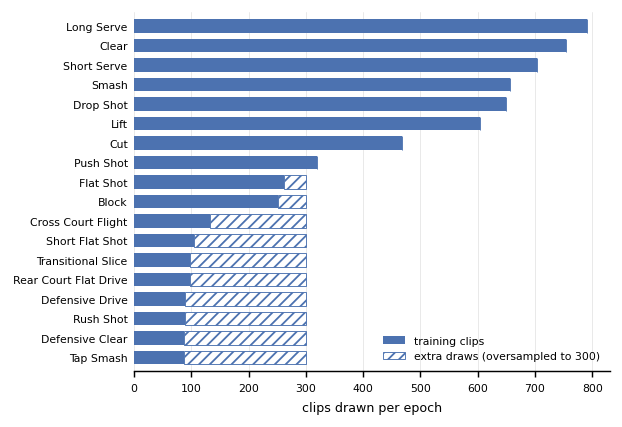

clips drawn per epoch: 7948 (train clips 6247)


In [12]:
short = [c.split("_", 1)[-1] for c in class_names]
n = train_counts.to_numpy()
drawn = np.maximum(n, TARGET)
order = np.argsort(n)                                  # least frequent first, so the most frequent ends up on top
y = np.arange(len(order))

fig, ax = plt.subplots(figsize=(WIDTH, 3.3))
ax.barh(y, n[order], color=NEAR, height=0.7, label="training clips")
ax.barh(y, (drawn - n)[order], left=n[order], color="white", edgecolor=NEAR, hatch="////", lw=0.5, height=0.7,
        label=f"extra draws (oversampled to {TARGET})")
ax.set_yticks(y, [short[k] for k in order])
ax.set_xlabel("clips drawn per epoch")
ax.set_xlim(0, max(drawn.max(), n.max()) * 1.05)
ax.set_ylim(-0.7, len(order) - 0.3)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", lw=0.3, alpha=0.5)
ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
save(fig, "fig_class_sampler")
plt.show()
print(f"clips drawn per epoch: {int(drawn.sum())} (train clips {int(n.sum())})")

## Figure 2: court aware selection

`CLIP_CLASS` picks the stroke class, `CLIP_INDEX` which of its clips with both players found (try other numbers for a clearer frame). The frame is read from `RAW_VIDEOS`; without the video it is drawn on a blank canvas.

841 Smash clips with both players
saved /workspace/outputs/figures/methodology/fig_selection.png


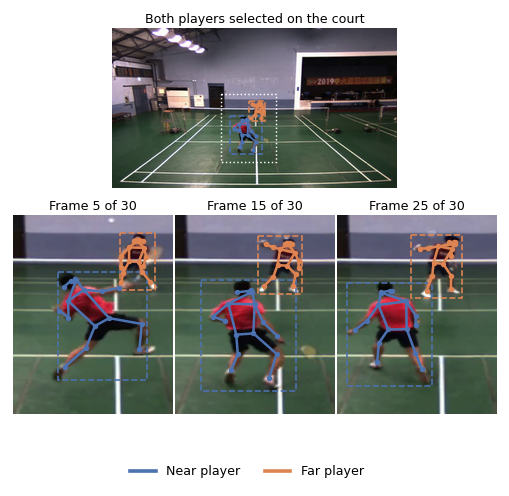

In [13]:
from matplotlib.lines import Line2D

CLIP_CLASS, CLIP_INDEX = "Smash", 0
SLOTS = (4, 14, 24)

log_files = sorted(f for f in glob.glob(f"{DATA}/extraction_sel_log*.csv") if os.path.getsize(f) > 0)
sel = pd.concat([pd.read_csv(f) for f in log_files], ignore_index=True).drop_duplicates("filepath", keep="last")
sel = sel[sel["status"] == "ok"].set_index("filepath")
cand = manifest[manifest["class_name"].str.endswith(CLIP_CLASS) & manifest["far_found"] & manifest["filepath"].isin(sel.index)]
cand = cand[(sel.loc[cand["filepath"], "n_persons"] == 2).to_numpy()].reset_index(drop=True)
print(len(cand), f"{CLIP_CLASS} clips with both players")
fp, cls = cand.loc[CLIP_INDEX, "filepath"], cand.loc[CLIP_INDEX, "class_name"]
stem = os.path.splitext(os.path.basename(fp))[0]
kps = np.load(f"{SEL_RAW}/{cls}/{stem}.npy")
boxes = np.load(f"{SEL_BOX}/{cls}/{stem}.npy")
targets = np.linspace(sel.loc[fp, "span_first"], sel.loc[fp, "span_last"], N_TARGET).round().astype(int)
cap = cv2.VideoCapture(f"{RAW_VIDEOS}/{fp}") if (cv2 is not None and os.path.exists(f"{RAW_VIDEOS}/{fp}")) else None


def frame_at(t):
    if cap is None:
        return None
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(targets[t]))
    ok, bgr = cap.read()
    return bgr[..., ::-1] if ok else None


def draw_person(ax, kp, box, colour, lw=1.4, ms=4):
    if box is None or np.isnan(box[0]):
        return
    vis = kp[:, 2] > CONF_MIN
    for a, b in ds.COCO_SKELETON:
        if vis[a] and vis[b]:
            ax.plot([kp[a, 0], kp[b, 0]], [kp[a, 1], kp[b, 1]], color=colour, lw=lw)
    ax.scatter(kp[vis, 0], kp[vis, 1], s=ms, color=colour, zorder=3)
    ax.add_patch(Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1], fill=False, ec=colour, lw=0.9, ls="--"))


okb = boxes[~np.isnan(boxes[:, :, 0])]
x0, y0 = okb[:, :2].min(axis=0)
x1, y1 = okb[:, 2:].max(axis=0)
mx, my = 0.06 * (x1 - x0), 0.10 * (y1 - y0)

fig = plt.figure(figsize=(WIDTH, 3.9))
gs = fig.add_gridspec(2, 6, height_ratios=[1.0, 1.3], hspace=0.12, wspace=0.04)

ax = fig.add_subplot(gs[0, 1:5])
img = frame_at(SLOTS[1])
if img is not None:
    ax.imshow(img, interpolation="lanczos")
    H, W = img.shape[:2]
else:
    W, H = 1280, 720
for p, c in ((0, NEAR), (1, FAR)):
    draw_person(ax, kps[p, SLOTS[1]], boxes[p, SLOTS[1]], c, lw=1.0, ms=2)
ax.add_patch(Rectangle((x0 - mx, y0 - my), (x1 - x0) + 2 * mx, (y1 - y0) + 2 * my, fill=False, ec="white", lw=0.8, ls=":"))
ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Both players selected on the court", fontsize=7, pad=3)

for k, t in enumerate(SLOTS):
    a = fig.add_subplot(gs[1, 2 * k:2 * k + 2])
    im = frame_at(t)
    if im is not None:
        a.imshow(im, interpolation="lanczos")
    draw_person(a, kps[0, t], boxes[0, t], NEAR)
    draw_person(a, kps[1, t], boxes[1, t], FAR)
    a.set_xlim(x0 - mx, x1 + mx); a.set_ylim(y1 + my, y0 - my); a.set_aspect("equal"); a.axis("off")
    a.set_title(f"Frame {t + 1} of {N_TARGET}", fontsize=7, pad=3)

fig.legend(handles=[Line2D([0], [0], color=NEAR, lw=2, label="Near player"),
                    Line2D([0], [0], color=FAR, lw=2, label="Far player")],
           loc="lower center", ncol=2, frameon=False, fontsize=7, bbox_to_anchor=(0.5, -0.03))
save(fig, "fig_selection")
plt.show()
if cap is not None:
    cap.release()

## Figure 3: augmentation policies

One real clip of the old skeleton array (`keypoints_interp`, pixel coordinates), then the same clip under the basic and the advanced policy, drawn after body normalisation as the model sees it. Random draws are fixed (seed) so the figure repeats. `AUG_CLASS` and `AUG_INDEX` choose the clip; change `AUG_SEED` if the draws leave a transformation nearly invisible.

saved /workspace/outputs/figures/methodology/fig_augmentation.png


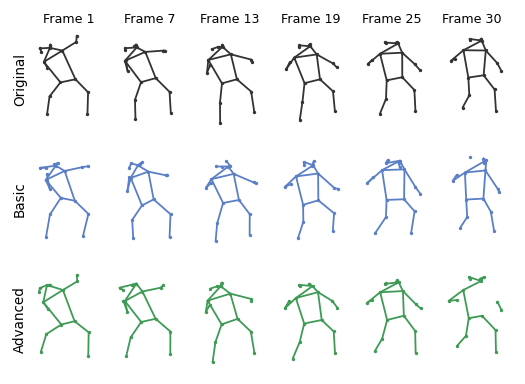

In [15]:
AUG_CLASS, AUG_INDEX, AUG_SEED = "Smash", 3, 1
FRAMES = (0, 6, 12, 18, 24, 29)

pool = manifest[manifest["class_name"].str.endswith(AUG_CLASS) & (manifest["split"] == "train")].reset_index(drop=True)
acls, afp = pool.loc[AUG_INDEX, "class_name"], pool.loc[AUG_INDEX, "filepath"]
kp0 = np.load(f"{OLD_INTERP}/{acls}/{os.path.splitext(os.path.basename(afp))[0]}.npy").astype(np.float32)


def apply_policy(kp, policy, seed):
    np.random.seed(seed)
    out = kp.copy()
    for fn in ds.AUGMENTATION_POLICIES[policy]:
        out = fn(out)
    return out


rows = [("original", kp0), ("basic", apply_policy(kp0, "basic", AUG_SEED)), ("advanced", apply_policy(kp0, "advanced", AUG_SEED))]
shown = [(name, ds.normalise_body(k)) for name, k in rows]
allxy = np.concatenate([k[list(FRAMES), :, :2].reshape(-1, 2) for _, k in shown])
lo, hi = np.nanpercentile(allxy, 1, axis=0) - 0.15, np.nanpercentile(allxy, 99, axis=0) + 0.15

fig, axes = plt.subplots(3, len(FRAMES), figsize=(WIDTH, 3.6), gridspec_kw=dict(wspace=0.0, hspace=0.0))
colours = {"original": "#333333", "basic": "#5b7fc7", "advanced": "#3f9a55"}
for r, (name, k) in enumerate(shown):
    for c, t in enumerate(FRAMES):
        a = axes[r, c]
        vis = k[t, :, 2] > CONF_MIN
        for i, j in ds.COCO_SKELETON:
            if vis[i] and vis[j]:
                a.plot([k[t, i, 0], k[t, j, 0]], [k[t, i, 1], k[t, j, 1]], color=colours[name], lw=1.0, solid_capstyle="round")
        a.scatter(k[t, vis, 0], k[t, vis, 1], s=3.5, color=colours[name], zorder=3, linewidths=0)
        a.set_xlim(lo[0], hi[0]); a.set_ylim(hi[1], lo[1]); a.set_aspect("equal"); a.axis("off")
        if r == 0:
            a.set_title(f"Frame {t + 1}", fontsize=7, pad=2)
    axes[r, 0].text(-0.02, 0.5, name.capitalize(), transform=axes[r, 0].transAxes, rotation=90, ha="right", va="center", fontsize=7.5)
save(fig, "fig_augmentation")
plt.show()

## Numbers quoted in the text

In [6]:
n_clips = len(manifest)
tab = pd.DataFrame({"train clips": train_counts.to_numpy(), "drawn per epoch": drawn,
                    "val": manifest[manifest["split"] == "val"]["class_name"].value_counts().reindex(class_names).to_numpy(),
                    "test": manifest[manifest["split"] == "test"]["class_name"].value_counts().reindex(class_names).to_numpy()}, index=short)
print(manifest["split"].value_counts().to_dict(), f"| {n_clips} clips | both players found in {int(manifest['far_found'].sum())} ({manifest['far_found'].mean():.1%})")
print(f"split shares: " + ", ".join(f"{k} {v / n_clips:.1%}" for k, v in manifest['split'].value_counts().items()))
print(f"clips drawn per epoch: {int(drawn.sum())}; limited sample classes (under {RARE_THRESHOLD}): {int(rare.sum())}")
tab.to_csv(f"{FIG}/class_counts.csv")
logger.report_table("class counts", "methodology", iteration=0, table_plot=tab.reset_index())
tab

{'train': 6247, 'test': 782, 'val': 781} | 7810 clips | both players found in 7622 (97.6%)
split shares: train 80.0%, test 10.0%, val 10.0%
clips drawn per epoch: 7948; limited sample classes (under 150): 8


,train clips,drawn per epoch,val,test
Short Serve,703,703,88,88
Cross Court Flight,133,300,17,16
Lift,604,604,76,76
Tap Smash,87,300,11,11
Block,252,300,32,31
Drop Shot,650,650,81,81
Push Shot,320,320,40,40
Transitional Slice,98,300,12,13
Cut,468,468,58,59
Rush Shot,89,300,11,12


('2022-08-30_19-19-43', '2023-05-02_20-34-08')
saved /workspace/outputs/figures/methodology/fig_court_region.png


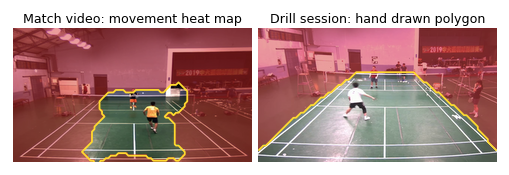

In [19]:
from matplotlib.colors import ListedColormap

COURT_VIDEOS = None            # e.g. ("2022-08-30_18-18-31", "2023-05-02_20-34-08"); None = automatic choice
regions = np.load(f"{DATA}/video_court_regions.npz")
allm = pd.read_csv(f"{DATA}/split_manifest.csv")
allm["video"] = allm["filepath"].apply(lambda p: os.path.splitext(os.path.basename(p))[0].split("_dataset")[0])
first_clip = allm.drop_duplicates("video").set_index("video")["filepath"]
counts = allm["video"].value_counts()
if COURT_VIDEOS is None:
    match_video = [v for v in counts.index if not v.startswith("2023-05-02")][0]
    COURT_VIDEOS = (match_video, "2023-05-02_20-34-08")
print(COURT_VIDEOS)


def court_panel(ax, v, title):
    cap = cv2.VideoCapture(f"{RAW_VIDEOS}/{first_clip[v]}")
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) // 2)
    ok, bgr = cap.read(); cap.release()
    img = bgr[..., ::-1]
    H, W = img.shape[:2]
    m = regions[v]
    ax.imshow(img, extent=(0, W, H, 0), interpolation="lanczos")
    outside = np.ma.masked_where(m, np.ones(m.shape))
    ax.imshow(outside, extent=(0, W, H, 0), cmap=ListedColormap(["#d62728"]), alpha=0.45, interpolation="nearest", vmin=0, vmax=1)
    ax.contour(np.linspace(0, W, m.shape[1]), np.linspace(0, H, m.shape[0]), m.astype(float), levels=[0.5], colors="#ffd92f", linewidths=1.0)
    ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=7, pad=3)


fig, axes = plt.subplots(1, 2, figsize=(WIDTH, 1.9), gridspec_kw=dict(wspace=0.03))
court_panel(axes[0], COURT_VIDEOS[0], "Match video: movement heat map")
court_panel(axes[1], COURT_VIDEOS[1], "Drill session: hand drawn polygon")
save(fig, "fig_court_region")
plt.show()

When the figures look right: copy `outputs/figures/methodology/*.pdf` (or the PNGs) into the Overleaf `figures/` folder, and `outputs/results/wrong_player_examples.png` from notebook 35 with them. If a figure needs another clip, change the index in its settings line and rerun only that cell.